In [1]:
import sys, json; sys.path.append("..")
import pandas as pd, shap
from src.train import make_lgbm

train = pd.read_csv("../data/processed/train.csv", index_col=0)
test = pd.read_csv("../data/processed/test.csv", index_col=0)
y_tr = train.pop("SeriousDlqin2yrs"); X_tr = train
y_te = test.pop("SeriousDlqin2yrs"); X_te = test

best = json.load(open("../reports/best_lgbm_params.json"))
model = make_lgbm(**best).fit(X_tr, y_tr)       # trained on training data only

X_s = X_te.sample(3000, random_state=42)        # a sample keeps it fast; we only explain, never tune
explainer = shap.TreeExplainer(model)
sv = explainer(X_s)
if sv.values.ndim == 3:                         # some shap versions return both classes
    sv = sv[:, :, 1]                            # keep "default" (class 1)

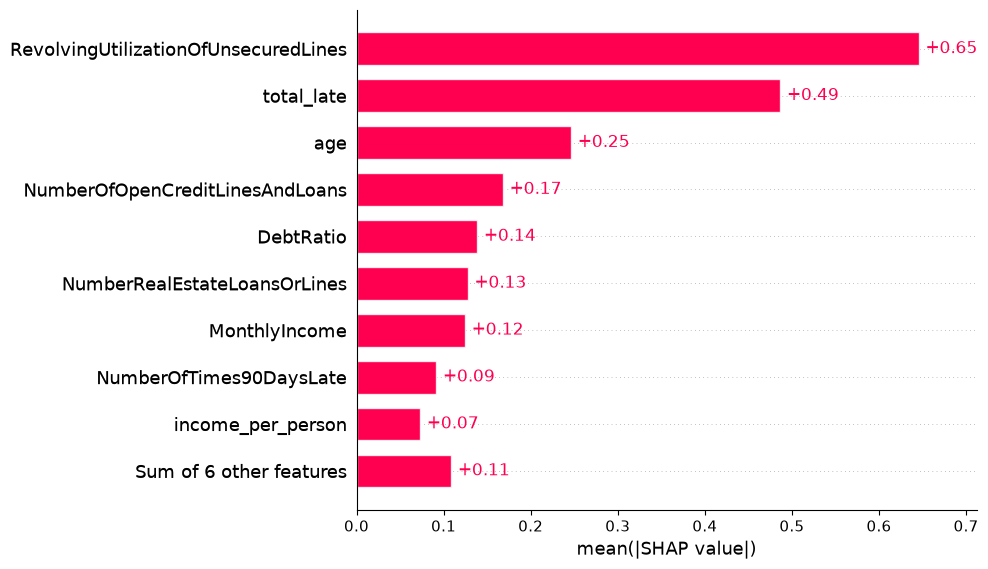

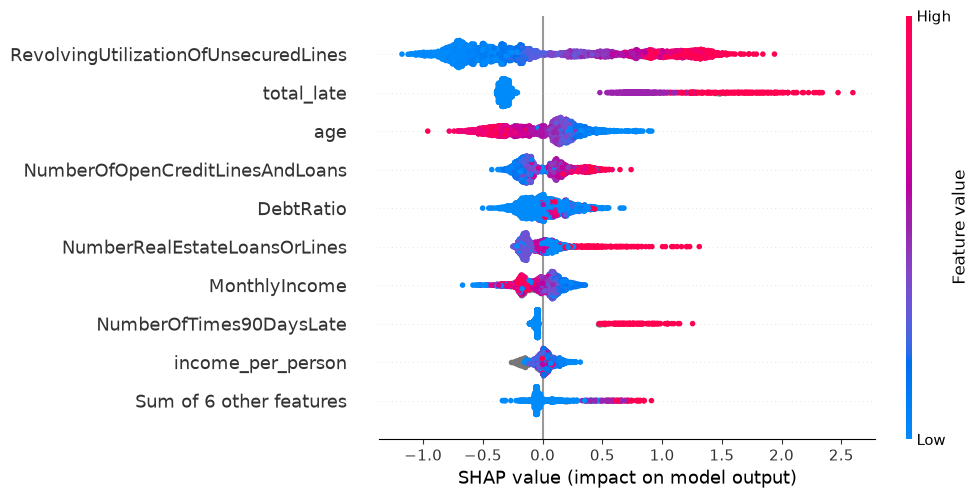

In [2]:
shap.plots.bar(sv, max_display=10)
shap.plots.beeswarm(sv, max_display=10)

risk score: 0.978 | actual outcome: 1


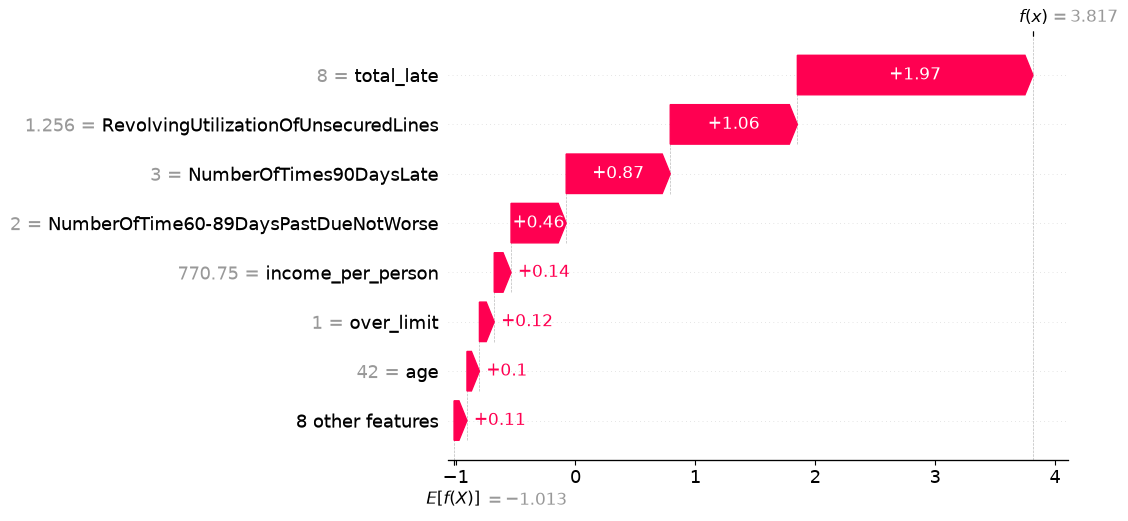

In [3]:
import numpy as np

risk = model.predict_proba(X_s)[:, 1]
i = int(np.argmax(risk))      # the riskiest borrower in our sample; try another number to explore
print("risk score:", round(risk[i], 3), "| actual outcome:", y_te.loc[X_s.index[i]])
shap.plots.waterfall(sv[i], max_display=8)